# CSE 242 — Assignment 1 Analysis

## Part 3, Q2: Scatter plot and correlation analysis.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from Assignment1 import generate_data

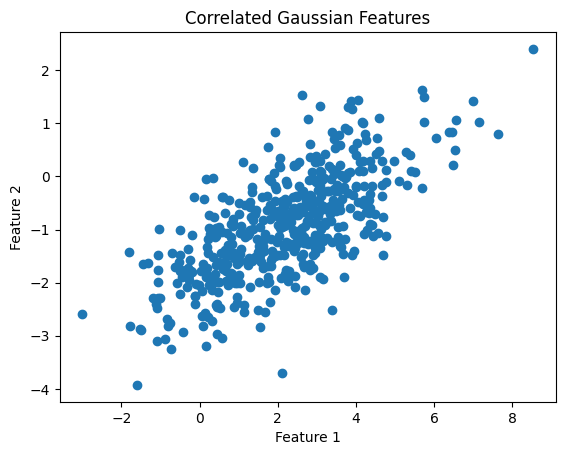

In [2]:
data = generate_data()

plt.scatter(data[:, 0], data[:, 1])
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Correlated Gaussian Features")
plt.show()

### Correlation Analysis

The two Gaussian features were generated using the covariance matrix

$$
\Sigma =
\begin{pmatrix}
3 & 1.2 \\
1.2 & 1
\end{pmatrix}.
$$

For two random variables $X_1$ and $X_2$, the correlation is

$$
\rho_{X_1,X_2}
=
\frac{\operatorname{Cov}(X_1,X_2)}
{\sqrt{\operatorname{Var}(X_1)\operatorname{Var}(X_2)}}.
$$

From the covariance matrix,

$$
\operatorname{Var}(X_1)=3, \qquad
\operatorname{Var}(X_2)=1, \qquad
\operatorname{Cov}(X_1,X_2)=1.2.
$$

Therefore, the theoretical correlation is

$$
\rho_{X_1,X_2}
=
\frac{1.2}{\sqrt{(3)(1)}}
\approx 0.693.
$$

This indicates a moderately strong positive correlation between the two
features. The scatter plot agrees with this value: the observations form
an upward-sloping elliptical pattern, meaning that larger values of
Feature 1 tend to occur with larger values of Feature 2. The relationship
is clearly positive but not perfectly linear, which is consistent with a
correlation of approximately $0.69$ rather than a correlation close to $1$.

## Part 3, Q3:  Implement PCA from scratch using NumPy.

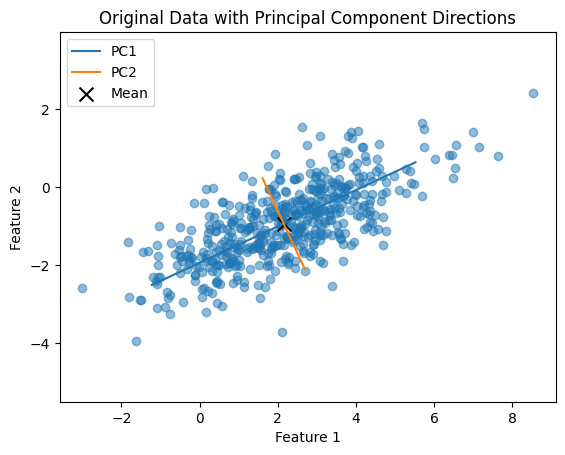

In [3]:
# Run PCA on the data

from Assignment1 import pca

results = pca(data)

mean = results["mean"]
components = results["components"]
eigenvalues = results["eigenvalues"]

# Plot the original data
plt.scatter(data[:, 0], data[:, 1], alpha=0.5)

# Scale the principal component directions by their standard deviations.
# From Q1, Var(u^T X) = lambda, so sqrt(lambda) is the standard
# deviation of the data along each principal component direction.
# Multiplying by 2 makes the directions easier to see on the plot.
pc1 = components[:, 0] * 2 * np.sqrt(eigenvalues[0])
pc2 = components[:, 1] * 2 * np.sqrt(eigenvalues[1])

# Plot PC1 through the mean.
# PC1 corresponds to the largest eigenvalue and therefore represents
# the direction of maximum variance.
plt.plot(
    [mean[0] - pc1[0], mean[0] + pc1[0]],
    [mean[1] - pc1[1], mean[1] + pc1[1]],
    label="PC1"
)

# Plot PC2 through the mean.
# PC2 is orthogonal to PC1 and represents the remaining direction
# of variance in the two-dimensional data.
plt.plot(
    [mean[0] - pc2[0], mean[0] + pc2[0]],
    [mean[1] - pc2[1], mean[1] + pc2[1]],
    label="PC2"
)

# Plot the mean of the data
plt.scatter(mean[0], mean[1], marker="x", s=100, label="Mean", color = "black")

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Original Data with Principal Component Directions")
plt.legend()
plt.axis("equal")
plt.show()

### Principal Component Visualization

The scatter plot shows the original two-dimensional Gaussian data along with the two principal component directions. PC1 follows the direction in which the data have the greatest variance and therefore aligns with the longer axis of the data. PC2 is orthogonal to PC1 and represents the direction of the remaining variance.

From Q1,

$$
\operatorname{Var}(u^T X) = u^T \Sigma u.
$$

PCA maximizes this variance, so PC1 is the eigenvector with the largest eigenvalue and represents the direction of maximum variance. The positive slope of PC1 is also consistent with the positive correlation observed between the two features in Q2.

## Part 3, Q4: Total variance explained by each principal component.

In [4]:

from Assignment1 import explained_variance

variance_fractions = explained_variance(eigenvalues)

print("Explained variance proportions:", variance_fractions)
print("PC1:", variance_fractions[0])
print("PC2:", variance_fractions[1])

Explained variance proportions: [0.89385326 0.10614674]
PC1: 0.8938532602077144
PC2: 0.10614673979228564


### Variance and PCA Discussion

PC1 explains 89.385% of the variance and PC2 explains the remaining 10.615%. This shows that most of the variation in the two-dimensional dataset is captured by PC1.

Dimensionality reduction could therefore be performed by keeping only PC1, reducing the data from two dimensions to one while retaining about 89.4% of the total variance. The trade-off is that removing PC2 would also discard about 10.6% of the variance. In general, keeping fewer principal components reduces the dimensionality and complexity of the data, but also results in some loss of information.

PCA is often used on high-dimensional datasets with hundreds of features, rather than datasets with only two features like the one in this problem. In these cases, PCA can reduce a large number of features to a smaller number of principal components that still capture most of the variation in the original data. This can make high-dimensional data easier to visualize, analyze, and work with.